# Notebook 06 - Chapters 4 and 5

Below you find exercises for Chapters 4 and 5. These exercises will prepare you in particular for the obligatory mid-term tests. The purpose of the prepared code snippets below is to give you some helpful structure for coding by predefining some useful variable names, but you do not need to use these prepared code snippets and prepared variable names if you do not want to. Do not hestitate to use the function `help()` to print the documentation of the functions that you need. If you are stuck, please ask one of the supervisors present.
<br>

Monte Carlo simulation can not only be used to compute prices of options but also to compute sensitivities of options. Here, we will use the finite differences method, the infinitesimal perturbation method and the likelihood ratio method. Afterwards, we will compute option prices using the explicit and the Crank&ndash;Nicolson finite differences scheme and plot option prices surfaces against the whole $(t, S(t))$ grid. Finally, we will demonstrate how to use Richardson extrapolation to improve the accuracy of American option pricing computations.

In the code snippet below, we define the variables $r$, $\sigma$, $T$, $K$ and $S(0)$ for the Black&ndash;Scholes model.

In [51]:
import os
import marshal
import types
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.special import eval_laguerre
print(os.getcwd())

r = 0.02
sigma = 0.3
T = 1.
K = 100
S0 = 100

/home/jovyan/my_materials


After running the import-statements above there should be a line displayed with `'/home/jovyan/my_materials'.`

<br>

## Step 1: Computation of sensitivities using Monte Carlo simulation

In the lecture notes we discussed three different methods to approximate sensitivities, i.e. derivatives of option prices with respect to input parameters, via Monte Carlo methods: The finite difference method, the infinitesimal perturbation method and the likelihood ratio method. We now want to implement each of these three methods and test their accuracy for the computation of the option delta, i.e. the first derivative of the option price $V(t)$ with respect to the current stock price $S(t)$, for a European call option in the Black&ndash;Scholes model.

**Task 1.1**: Write a function `delta_BS_MC_FD(t, St, K, T, r, sigma, N, h, seed)` that performs the finite difference method for the computation of the delta as described on page 60 in the lecture notes. In other words, the function should simulate $\frac{Z_n(S(t) + \frac{h}{2}) - Z_n(S(t) - \frac{h}{2})}{h}$ for $\smash{Z_n(s) = e^{-r(T-t)} \Big(s \exp\big( (r−\sigma^2/2)(T-t) +\sigma \sqrt{T - t} X_n\big)−K\Big)^+}$ with standard normally distributed random variables $X_n$. The function should take the number $N$ of simulations as well as the step size $h$ as input arguments and should return both the finite difference estimator $\widehat z'(s)$ for the delta and the sample variance $\widehat{\mathrm{Var}}(\widehat z'(s))$ of this estimator. Additionally, the function should take an argument `seed` that specifies the numpy random seed.

*Useful Python commands*: `rng.normal`, `np.maximum`, `np.exp`, `np.sqrt`, `np.var`, `np.mean`

In [52]:
def delta_BS_MC_FD(t, St, K, T, r, sigma, N, h, seed):
    rng = np.random.default_rng(seed=seed)
    X = rng.normal(loc=0, scale=1, size=N)

    Z_plus = np.maximum((St + h / 2) * np.exp((r - sigma ** 2 / 2) * (T - t) + sigma * np.sqrt(T - t) * X) - K, 0)
    Z_minus = np.maximum((St - h / 2) * np.exp((r - sigma ** 2 / 2) * (T - t) + sigma * np.sqrt(T - t) * X) - K, 0)
    # payoffs = np.maximum((St + h / 2) * np.exp((r - sigma ** 2 / 2) * T + sigma * np.sqrt(T) * X) - K, 0) - np.maximum((St - h / 2) * np.exp((r - sigma ** 2 / 2) * T + sigma * np.sqrt(T) * X) - K, 0)
    Z_prime = np.exp(-r * T) / h * (Z_plus - Z_minus)
    var_estimator = np.var(Z_prime) / N
    return np.mean(Z_prime), var_estimator 

print(delta_BS_MC_FD(0, S0, K, T, r, sigma, 1230, 890, 20)) # OK

### Uncomment and execute the following line only if you obtained no result:
delta_BS_MC_FD1 = types.FunctionType(marshal.load(open('../shared_materials/objects/6_1_1.mar', 'rb')), globals())
print(delta_BS_MC_FD1(0, S0, K, T, r, sigma, 1230, 890, 20))

(np.float64(0.4876772020672385), np.float64(2.742817089533769e-05))
(np.float64(0.4876772020672385), np.float64(2.742817089533769e-05))


**Task 1.2**: Write a function `delta_BS_MC_IP(t, St, K, T, r, sigma, N, seed)` that performs the infinitesimal perturbation method for the computation of the delta as described on page 61 of the lecture notes. In other words, the function should simulate $Z'_n(S(t))$ for $Z'_n(s) = 1_{\{s \exp((r−\sigma^2/2)(T-t)+\sigma \sqrt{T-t}X_n)>K\}}  \exp( − \sigma^2(T-t)/2 + \sigma \sqrt{T-t} X_n)$ with standard normally distributed random variables $X_n$. The function should take the number $N$ of simulations as an input argument and should return both the infinitesimal perturbation estimator for the delta and the sample variance of this estimator. Additionally, the function should take an argument `seed` that specifies the numpy random seed.

*Useful Python commands*: `rng.normal`, `np.exp`, `np.sqrt`, `np.var`, `np.mean`

In [53]:
def delta_BS_MC_IP(t, St, K, T, r, sigma, N, seed):
    rng = np.random.default_rng(seed=seed)
    X = rng.normal(loc=0, scale=1, size=N)
    Z_s = St * np.exp((r - sigma ** 2 / 2) * (T - t) + sigma * np.sqrt(T - t) * X)
    
    Z_prime = (Z_s > K) * np.exp(-(sigma ** 2) * (T - t) / 2 + sigma * np.sqrt(T - t) * X)
        
    var_estimator = np.var(Z_prime) / N
    return np.mean(Z_prime), var_estimator 

print(delta_BS_MC_IP(0, S0, K, T, r, sigma, 12390, 20)) # OK

### Uncomment and execute the following line only if you obtained no result:
delta_BS_MC_IP1 = types.FunctionType(marshal.load(open('../shared_materials/objects/6_1_2.mar', 'rb')), globals())
print(delta_BS_MC_IP1(0, S0, K, T, r, sigma, 12390, 20))

(np.float64(0.5841828651619144), np.float64(3.383630888003833e-05))
(np.float64(0.5841828651619144), np.float64(3.383630888003833e-05))


We now want to use these functions to compute Monte Carlo estimates for the time 0 delta of a European call option with strike $K = 100$ and all other variables set as at the top of this notebook.

**Task 1.3**: Set $N = 50\,000$ and $h = 10^{-6}$. Compute the finite difference and infinitesimal perturbation estimators for the delta $\smash{\frac{\partial}{\partial S(0)} V(0)}$ of the call option price and store them in variables `delta_FD` and `delta_IP`, respectively. Use the numpy random seed 10 for the finite difference method and the seed 20 for the infinitesimal perturbation method. Afterwards, compute the true value of the option delta in the Black&ndash;Scholes model (given by $\Phi(d_1)$, see page 28 of the lecture notes) and store it in a variable delta. Print all three values.

*Useful Python commands*: `np.log`, `np.sqrt`

In [54]:
N = 50000
h = 1e-6

delta_FD, _ = delta_BS_MC_FD(0, S0, 100, T, r, sigma, N, h, 10) # , _ being used so we can take out the values
delta_IP, _ = delta_BS_MC_IP(0, S0, 100, T, r, sigma, N, 20)
d1 = (np.log(S0/K) + (r + sigma ** 2 / 2) * T) / (sigma * np.sqrt(T))
delta = norm.cdf(d1)

print(delta_FD) # Should be fine
print(delta_IP) # OK
print(d1) # OK
print(delta) # OK


### Uncomment and execute the following line only if you obtained no result:
#delta_FD, delta_IP, d1, delta = 0.5836985359992226, 0.5860710072927078, 0.21666666666666667, 0.5857659364695248

print(r'FD value of phi_1: {:.5f}. IP value of phi_1: {:.5f}. True Value of phi_1: {:.5f}'.format(delta_FD, delta_IP, delta))

0.583698535987426
0.5860710072927078
0.21666666666666667
0.5857659364695248
FD value of phi_1: 0.58370. IP value of phi_1: 0.58607. True Value of phi_1: 0.58577


The choice of the step size $h$ in the finite difference method is an example of a bias-variance tradeoff often encountered in statistics: Choosing $h$ small reduces the bias of the estimate but increases the variance, choosing $h$ large increases the bias but reduces the variance.  As detailed on pages 59&ndash;60 in the lecture notes, one can choose $h$ in an optimal way to minimize the mean squared error (MSE) of the finite difference estimate. We now want to estimate the MSE of the finite difference method for different values of $h$ and compare it to the MSE of the infinitesimal perturbation method.

The MSE of the finite difference estimator $\widehat z'(s)$ is approximately given by $\big(\frac{h^2}{24} z'''(s) \big)^2 + \widehat{\mathrm{Var}}(\widehat z'(s))$ (see the bottom of page 59 of the lecture notes). Since the sample variance $\widehat{\mathrm{Var}}(\widehat z'(s))$ is already returned by the function `delta_BS_MC_FD`, we are only left to compute the squared bias $\big(\frac{h^2}{24} z'''(s) \big)^2$ to compute the MSE. Here, $z'''(s)$ is the third derivative of the $V(t)$ with respect to $S(t)=s$ (sometimes called the *speed* of the option) and is given by $z'''(s) = \frac{\varphi(d_1)}{s^2 \sigma \sqrt{T - t}} (\frac{d_1}{\sigma \sqrt{T-t}} + 1)$ in the case of a European call option, where $\varphi$ is the pdf of the standard normal distribution.

**Task 1.4**: Compute the speed $z'''(S(0))$ of the European call option $V(0)$ and store it in a variable `speed`.

*Useful Python commands*: `np.sqrt`. The pdf of a standard normal distribution can be accessed using the scipy.stats function `norm.pdf`.

In [55]:
speed = norm.pdf(d1) / ((S0 ** 2) * sigma * np.sqrt(T)) * ((d1 / (sigma * np.sqrt(T))) + 1) 
print(speed) # OK

### Uncomment and execute the following line only if you obtained no result:
# speed = 0.00022370935375918568

0.00022370935375918568


**Task 1.5**: Define an array `h_range` that contains 1000 logarithmically spaced values of $h$ between $10^{-3}$ and $10^{1}$. Then, use a for-loop to compute the MSE of the finite difference estimator for each $h$ in the array `h_range` and store the MSE values in an array `mse_FD`. Also, compute the MSE of the infinitesimal perturbation method (which is just the variance of the estimator since it is unbiased) and store it in a variable `mse_IP`. Use the numpy random seed 10 for reproducibility. Afterwards, plot the MSE estimates stored in the array `mse_FD` against $h$ and draw a horizontal line at the height of the MSE `mse_IP`. Use the command `plt.semilogx` instead of the command `plt.plot` to obtain a logarithmic spacing of the $x$ axis. Interpret your result using a comment.

*Useful Python commands*: `np.logspace`, `np.geomspace`, `np.mean`, `plt.axhline`

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/6_1_5.png" width="550"><details>
  <summary>Interpretation:</summary> Since the MSE of the infinitesimal perturbation method does not depend on the step size $h$, it can be represented by a straight line in the plot. The infinitesimal perturbation yields unbiased estimates of the delta, so the MSE is completely dominated by the variance of the estimator. For $h \to 0$, the bias of the finite difference estimator converges to 0, so in the limit for $h \to 0$, the MSE of the finite difference method is also completely dominated by the variance of the estimator, which seems to be on the same level as the variance of the infinitesimal perturbation estimator (this is a consequence of using the same random seed for both methods). For larger $h$ however, the variance of the finite difference estimator gets smaller while its bias grows. This constitutes a classic bias-variance tradeoff and one can observe that the combined MSE of the finite difference estimator is minimized somewhere around $h \approx 5$.

 </details>
</details>

8.401857072562904e-06


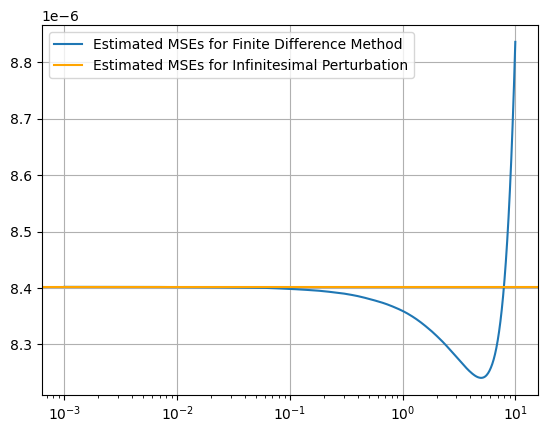

In [56]:
h_range = np.logspace(-3, 1, num=1000) # equivalent to 10 ** np.linspace(-3, 1, 5)
#print(h_range)
mse_FD = np.zeros(1000)

for i in range(1000):
    _, var_estimate_FD = delta_BS_MC_FD(0, S0, K, T, r, sigma, N, h = h_range[i], seed=10)
    bias = (h_range[i] ** 2 / 24 * speed) ** 2
    mse_FD[i] = bias + var_estimate_FD

_, mse_IP = delta_BS_MC_IP(0, S0, K, T, r, sigma, N, seed=10)

### Uncomment and execute the following lines only if you obtained no result:
#h_range1, mse_FD1 = np.loadtxt('../shared_materials/objects/6_1_5.txt')
#mse_IP1 = 8.401857072562904e-06
#print(np.round(h_range, 5) == np.round(h_range1, 5))
#print(np.round(mse_FD, 5) == np.round(mse_FD1, 5)) # All True
#print(mse_FD) # Should be fine
print(mse_IP) # OK

plt.semilogx(h_range, mse_FD, label = 'Estimated MSEs for Finite Difference Method')
plt.axhline(mse_IP, color = 'orange', label = 'Estimated MSEs for Infinitesimal Perturbation')
plt.legend()
plt.grid()
plt.show()

# Interpretation: ...

Finally, we want to use the likelihood ratio method to compute an option delta. To introduce some variety, we will not consider a European call option but a binary call option with strike $K$ and payoff $\mathbf{1}_{\{S(T) \geq K\}}$.

**Task 1.6**: Write a function `delta_binary_BS_MC_LR(t, St, K, T, r, sigma, N, seed)` that performs the likelihood ratio method for the computation of the delta of the binary call option. In other words, the function should simulate $f(X_n) \frac{d\log(g_{S(t)}(X_n))}{ds}$ with $N(\log(S(t)) / \sqrt{\sigma^2 T}, 1)$-distributed random variables $X_n$ for \begin{equation} f(x) = e^{-r(T-t)}1_{\Big\lbrace\exp( (r− \sigma^2 / 2)(T-t) + \sigma \sqrt{T-t} x) \geq K\Big\rbrace} \quad \text{and}\quad\frac{d\log(g_s(x))}{ds} = \frac{x}{s\sigma \sqrt{T-t}} - \frac{\log s}{s \sigma^2 T}.\end{equation} The function should take the number $N$ of simulations as an input argument and should return both the likelihood ratio estimator for the delta and the sample variance of this estimator. Additionally, the function should take an argument `seed` that specifies the numpy random seed.

*Useful Python commands*: `rng.normal`, `np.exp`, `np.sqrt`, `np.log`, `np.var`, `np.mean`

In [57]:
def delta_binary_BS_MC_LR(t, St, K, T, r, sigma, N, seed):
    rng=np.random.default_rng(seed=seed)
    X = rng.normal(loc = np.log(St) / np.sqrt((sigma ** 2) * T), scale = 1, size = N)
    Z_s = np.exp((r - sigma ** 2 / 2) * (T - t) + sigma * np.sqrt(T - t) * X)
    
    Z_prime = (Z_s > K) * np.exp(-r * (T - t)) * ((X / (St * sigma * np.sqrt(T - t))) - (np.log(St) / (St * sigma**2 * T)))
        
    var_estimator = np.var(Z_prime) / N

    return np.mean(Z_prime), var_estimator 

print(delta_binary_BS_MC_LR(0, S0, K, T, r, sigma, N, 20)) # OK

### Uncomment and execute the following line only if you obtained no result:
delta_binary_BS_MC_LR1 = types.FunctionType(marshal.load(open('../shared_materials/objects/6_1_6.mar', 'rb')), globals())
print(delta_binary_BS_MC_LR1(0, S0, K, T, r, sigma, N, 20))

(np.float64(0.012930078513746663), np.float64(7.225550894280351e-09))
(np.float64(0.012930078513746663), np.float64(7.225550894280351e-09))


We now want to visualize how the MSE of the likelihood ratio estimator for the delta of the binary call depends on the level of the strike $K$.

**Task 1.7**: Define an array `K_range` containing 1000 equally spaced values of the strike $K$ between 10 and 300. Then use a for-loop to compute the MSE (i.e. the sample variance) of the likelihood ratio estimator of the binary call option delta at time 0 for each value of $K$ in the array `K_range`. Use the numpy random seed 20 for reproducibility. Plot the MSE values against the values of $K$ and interpret your result using a comment.

*Useful Python commands*: `np.linspace`

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/6_1_7.png" width="550"><details>
  <summary>Interpretation:</summary> As $K$ becomes larger, the MSE of the likelihood ratio estimator converges to 0. In the at-the-money strike range $K \approx 100$, the MSE shows a slight upwards tilt, which originates from the discontinuity of the payoff of the binary option at $K = 100$.

 </details>
</details>

True
True


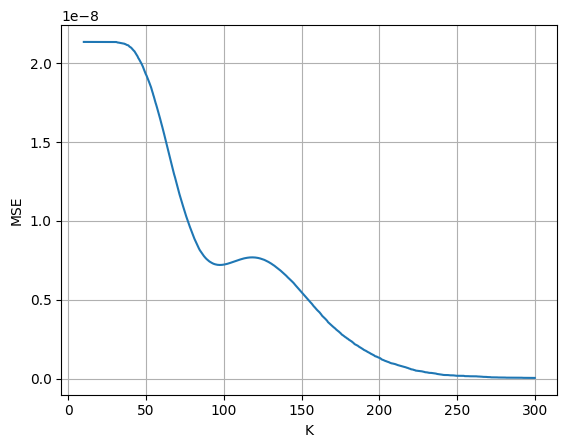

In [58]:
K_range = np.linspace(10, 300, 1000)
mse_LR = np.zeros(1000)
for i in range(1000):
    _, var_estimate_LR = delta_binary_BS_MC_LR(0, S0, K_range[i], T, r, sigma, N, 20)
    mse_LR[i] = var_estimate_LR


### Uncomment and execute the following line only if you obtained no result:
K_range1, mse_LR1 = np.loadtxt('../shared_materials/objects/6_1_7.txt')

print(np.array_equal(K_range, K_range1)) # True
print(np.array_equal(mse_LR1, mse_LR)) # True

plt.plot(K_range, mse_LR)
plt.grid()
plt.xlabel('K')
plt.ylabel('MSE')
plt.show()

# Interpretation: ...

In [59]:
# The MSE of the likelihood ratio estimator converges to 0 for very large strikes because the option never pays off, 
# but it shows a slight upward tilt near the at-the-money strike because the binary option's discontinuous payoff 
# creates instability in the LR method when many simulated paths end up near the strike price.

<br>

## Step 2: Computation of American option prices using the Longstaff&ndash;Schwartz algorithm

The Longstaff&ndash;Schwartz algorithm is a sophisticated method to compute prices of American options using Monte Carlo simulation, which is a highly non-trivial task. The main idea underlying the Longstaff&ndash;Schwartz algorithm is to approximate the *continuation value* of the American option by regressing it on a set of basis functions $\ell_0, \ell_1, \dots, \ell_M$ of the Hilbert space $L^2(\mathbb{R}_+, \mathscr{B}_+, \mu)$ with some probability measure $\mu$. Often, one chooses $\ell_k$ to be the *Laguerre polynomials*. In the following, we will choose $M = 3$. We now want to implement the full algorithm given on pages 71&ndash;72 of the lecture notes.

In a first step, one needs to simulate $N$ paths of the stock price with a discretization step size $\Delta t = T / M$.

**Task 2.1**: Fill the blank spaces in the code snippet below to simulate $N = 10\,000$ paths of a geometric Brownian motion with $m = 1000$ using the Euler scheme.

*Useful Python commands*: `np.sqrt`

In [60]:
m = 1000
N = 10000
M = 3
dt = T / m

rng = np.random.default_rng(seed=20)
dWt = rng.normal(0, np.sqrt(dt), (N, m))
S = np.zeros((N, m + 1))

S[:, 0] = S0
for t in range(1, m + 1):
    S[:, t] = S[:, t - 1] + r * S[:, t - 1] * dt + sigma * S[:, t - 1] * dWt[:, t - 1]

print(dWt)
print(S)

### Uncomment and execute the following line only if you obtained no result:
dWt1, S1 = np.loadtxt('../shared_materials/objects/6_2_1a.txt'), np.loadtxt('../shared_materials/objects/6_2_1b.txt')
print(np.array_equal(dWt, dWt1)) # True
print(np.array_equal(S, S1)) # True

[[-0.01137372  0.03806355  0.04417285 ...  0.00950927  0.0178238
  -0.00449554]
 [ 0.00841641  0.02018243  0.0140203  ...  0.03296518 -0.00282144
   0.01529469]
 [ 0.02576237 -0.06245736 -0.0049955  ...  0.02482989  0.00714792
  -0.01480114]
 ...
 [ 0.01885731  0.00131198 -0.04055355 ...  0.00591639  0.05610788
   0.02602853]
 [-0.02934413 -0.03174904  0.00826168 ...  0.02013086 -0.01422903
   0.01800005]
 [-0.05773302 -0.02814739  0.00311147 ... -0.02612058 -0.00034466
  -0.01671013]]
[[100.          99.66078854 100.80081475 ...  41.72116442  41.94508777
   41.88935693]
 [100.         100.25449233 100.86351122 ...  63.01485435  62.9627769
   63.25293493]
 [100.         100.77487106  98.88864671 ...  68.65299355  68.80158453
   68.49745791]
 ...
 [100.         100.56771929 100.60931354 ... 235.46990584 239.43813076
  241.31258655]
 [100.          99.12167596  98.17955311 ... 117.06374376 116.56637407
  117.19816557]
 [100.          98.2700094   97.44216166 ... 159.22958209 159.2163026


**Task 2.2**: Define an array `tau` that is supposed to contain the optimal exercise times $\tau_n$, $n \in \{1, \dots, N\}$. Initialize the array `tau` with $\tau_n \equiv T$. Define another array `g` containing the $N$ values $g_n = (K - S_{n, m})^+$ for  $n \in \{1, \dots, N\}$, which will later be updated to contain the payoffs at the optimal exercise times $\tau_n$.

*Useful Python commands*: `np.repeat`, `np.maximum`

In [61]:
tau = np.repeat(T, N)
print(tau)
g = np.maximum(K - S[:, m], 0)
print(g)

### Uncomment and execute the following line only if you obtained no result:
tau1, g1 = np.loadtxt('../shared_materials/objects/6_2_2.txt')
print(np.array_equal(tau, tau1)) # True
print(g1)
print(np.array_equal(g, g1)) # True

[1. 1. 1. ... 1. 1. 1.]
[58.11064307 36.74706507 31.50254209 ...  0.          0.
  0.        ]
True
[58.11064307 36.74706507 31.50254209 ...  0.          0.
  0.        ]
True


**Task 2.3**: Fill the blank spaces in the code below, which is supposed to compute the $t$-**loop** section of the algorithm from page 71 of the lecture notes. It stores the output $V_0$ of the algorithm in a variable `V0` and additionally computes the half-width of a 95\% confidence interval for $V_0$ and stores it in a variable `epsilon_95`.

*Useful Python commands*: The scipy.special command `eval_laguerre(k, x)` evaluates the $k$-th Laguerre polynomial $\ell_k(x)$ at some point $x$. The command `np.linalg.lstsq(x, y)[0]` performs the least-squares linear regression $y_n = \sum_{k=0}^M a_k x_{n, k}$ for a given array `y` containing $y_n$ and a given matrix `x` containing $x_{n, k}$ and returns the array of $a_k$ values.

*Useful Python commands*: `np.exp`, `np.maximum`

In [62]:
for i in range(m - 1, 0, -1):
    ITM = np.where(K - S[:, i] > 0)[0]  # in-the-money indices
    if ITM.shape[0] == 0:
        continue  # if no path is in the money, skip the iteration
        
    y = np.exp(-r * (tau[ITM] - i * dt)) * g[ITM]
    x = np.vstack([eval_laguerre(k, S[ITM, i]) for k in range(M + 1)]).T
    a = np.linalg.lstsq(x, y, rcond = None)[0]

    exercise_check = ITM[np.maximum(K - S[ITM, i], 0) >= np.sum((x * a), axis = 1)] # early exercise indices
    tau[exercise_check] = i * dt
    g[exercise_check] = np.maximum(K - S[exercise_check, i], 0)

V0 = np.maximum(np.maximum(K - S0, 0), np.mean(np.exp(-r * tau) * g))
epsilon_95 = 1.96 * np.sqrt(np.var(np.exp(-r * tau) * g, ddof=1) / N)

print(V0) # OK
print(epsilon_95) # OK

### Uncomment and execute the following lines only if you obtained no result:
# tau, g = np.loadtxt('../shared_materials/objects/6_2_3.txt')
# V0, epsilon_95 = 11.082910233569015, 0.23245111263567772

11.082910233569015
0.23245111263567772


The code snippet below contains a function `american_put_CRR(S0, K, T, r, sigma, M)` that computes the price of an American option in the binomial model with `M` steps. We now want to use this function to compute a reference value for the American option price so we can test the Longstaff&ndash;Schwartz algorithm above.

**Task 2.4**: Use the function `american_put_CRR` to define a variable `V0_CRR` that contains the price $V(0)$ of the American call option with strike $K = 100$ and all other variables as set in the beginning of the notebook in the binomial model with $M = 10000$ steps. Then print the CRR reference price next to the Longstaff&ndash;Schwartz option price stored in the variable `V0` and also print the 95\% error of the Longstaff&ndash;Schwartz estimate stored in the variable `epsilon_95`. Interpret and assess your result using a comment.

<details>
  <summary>Interpretation:</summary> 
    
> The reference price computed by the binomial model is given by $V(0) \approx 11.01309$. The American option price approximated by the Longstaff&ndash;Schwartz algorithm is approximately given by $V_0 \approx 11.08291$. Its 95% confidence interval has a radius of approximately $0.23245$, so that a 95% confidence interval for the Longstaff&ndash;Schwartz estimate is given by $[10.78064, 11.24554]$, which contains the reference price. Given the fact that the computation time of the Longstaff&ndash;Schwartz algorithm with $N = 10000$ simulations is not much shorter than the computation time of the binomial model with $M = 10000$, it seems that the binomial model is much superior to the Longstaff&ndash;Schwartz algorithm for computation of American option prices in the Black&ndash;Scholes model. The advantage of the Longstaff&ndash;Schwartz algorithm, on the other hand, lies its larger flexibility in the choice of the stochastic model: While the binomial model is bound to approximating option prices in the Black&ndash;Scholes model, the Longstaff&ndash;Schwartz algorithm can be used for any Markovian model for the stock price that can be simulated, like for example the Heston model.

 </details>

In [63]:
def american_put_CRR(S0, K, T, r, sigma, M): 
    delta_t = T / M
    alpha = np.exp(r * delta_t)
    beta = 1 / 2 * (alpha ** (-1) + alpha * np.exp(sigma ** 2 * delta_t))
    u = beta + np.sqrt(beta ** 2 - 1)
    d = 1 / u
    q = (alpha - d) / (u - d)

    value = np.maximum(K - S0 * u ** (2 * np.arange(M + 1) - M), 0)
    for i in range(M - 1, -1, -1):
        upsteps, downsteps = value[1:], value[:-1]
        value = alpha ** (-1) * (q * upsteps + (1 - q) * downsteps)
        payoffs = np.maximum(K - S0 * u ** (2 * np.arange(i + 1) - i), 0)
        value = np.maximum(value, payoffs)
    return value[0]

V0_CRR = american_put_CRR(S0, K, T, r, sigma, 10000)

print(V0_CRR)

### Uncomment and execute the following line only if you obtained no result:
# V0_CRR = 11.013087054306494

print('CRR reference price: {:.5f}, MC price: {:.5f}, 95% error: {:.5f}'.format(V0_CRR, V0, epsilon_95))

# Interpretation: ...

11.013087054306494
CRR reference price: 11.01309, MC price: 11.08291, 95% error: 0.23245


In [64]:
def american_put_CRR(g2, S0, T, r, sigma, M):
    delta_t = T / M

    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - 1)
    d = 1 / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    V[:, M] = g2(S[:, M])

    # Backward induction
    for i in range(M, 0, -1):
        V[:i, i-1] = np.maximum(g2(S[:i, i - 1]), np.exp(-r * delta_t) * (
            q * V[1:i+1, i] + (1 - q) * V[:i, i]
        ))

    return V[0, 0]

K = 100
g2 = lambda S: np.maximum(K - S, 0)  # European Put

price = american_put_CRR(g2, S0, T, r, sigma, M=10000)
print(price)

11.013087054300414


<br>

## Step 3: Computation of European call option price surfaces using the explicit finite difference method

Finite differences methods from Chapter 5 of the lecture are probably the most widely used tools for option pricing in practice because they are totally flexible in the payoff, can be generalized to work for many sophisticated stochastic models and are able to compute the whole surface of option prices across a two-dimensional $(t, S(t))$-grid. In the following, we want to implement the explicit finite differences scheme, which is given in pseudo-code on pages 75&ndash;76 of the lecture notes (with zero boundary conditions), for a European call option in the Black&ndash;Scholes model. The explicit finite differences scheme has the disadvantage that it becomes numerically instable if the number $m$ of discretized points of the (transformed) stock is chosen too large.

The code snippet below defines the input values $a = -0.7$, $b=0.4$ and $\nu_\max=2000$ for the algorithm.

**Task 3.1**: Define a variable `m` that contains the largest possible integer value of $m$ so that the explicit scheme with the above chosen values for $a$, $b$ and $\nu_\max$ is stable. Recall that the explicit finite differences scheme is stable as long as $\sigma^2 T/(2\nu_\max) < (b−a)^2/(2m^2)$. 

*Useful Python commands*: `int`, `np.sqrt`

In [65]:
a = -0.7
b = 0.4
nu_max = 2000
m = int((b - a) / (sigma * np.sqrt(T)) * np.sqrt(nu_max))
print(m) # OK

### Uncomment and execute the following line only if you obtained no result:
# m = 163

163


**Task 3.2**: Define the variables $q$, $\Delta \widetilde x$, $\Delta \widetilde t$ and $\lambda$ from the explicit scheme on pages 74-75 of the lecture notes.

In [66]:
q = 2 * r / (sigma ** 2) 
delta_x = (b - a) / m
delta_t = (sigma ** 2) * T / (2 * nu_max)
fidi_lambda = delta_t / (delta_x ** 2)

print(q) # OK
print(delta_x) # OK
print(delta_t) # OK
print(fidi_lambda) # OK

### Uncomment and execute the following line only if you obtained no result:
# q, delta_x, delta_t, fidi_lambda = 0.4444444444444445, 0.006748466257668713, 2.2499999999999998e-05, 0.49405165289256175

0.4444444444444445
0.006748466257668713
2.2499999999999998e-05
0.49405165289256175


**Task 3.3**: Define an array `x` that contains the $m + 1$ equally spaced values $\widetilde x_i = a + i \Delta \widetilde x$ as well as an array `t` that contains the $\nu_\max + 1$ equally spaced values $\widetilde t_i = i \Delta \widetilde t$.

*Useful Python commands*: `np.linspace`

In [67]:
x = np.linspace(a, b, m + 1)
t = np.linspace(0, nu_max * delta_t, nu_max + 1)

print(x)
print(t)

### Uncomment and execute the following line only if you obtained no result:
x1, t1 = np.loadtxt('../shared_materials/objects/6_3_3a.txt'), np.loadtxt('../shared_materials/objects/6_3_3b.txt')
print(np.array_equal(x, x1)) # True
print(np.array_equal(t, t1)) # True

[-0.7        -0.69325153 -0.68650307 -0.6797546  -0.67300613 -0.66625767
 -0.6595092  -0.65276074 -0.64601227 -0.6392638  -0.63251534 -0.62576687
 -0.6190184  -0.61226994 -0.60552147 -0.59877301 -0.59202454 -0.58527607
 -0.57852761 -0.57177914 -0.56503067 -0.55828221 -0.55153374 -0.54478528
 -0.53803681 -0.53128834 -0.52453988 -0.51779141 -0.51104294 -0.50429448
 -0.49754601 -0.49079755 -0.48404908 -0.47730061 -0.47055215 -0.46380368
 -0.45705521 -0.45030675 -0.44355828 -0.43680982 -0.43006135 -0.42331288
 -0.41656442 -0.40981595 -0.40306748 -0.39631902 -0.38957055 -0.38282209
 -0.37607362 -0.36932515 -0.36257669 -0.35582822 -0.34907975 -0.34233129
 -0.33558282 -0.32883436 -0.32208589 -0.31533742 -0.30858896 -0.30184049
 -0.29509202 -0.28834356 -0.28159509 -0.27484663 -0.26809816 -0.26134969
 -0.25460123 -0.24785276 -0.24110429 -0.23435583 -0.22760736 -0.2208589
 -0.21411043 -0.20736196 -0.2006135  -0.19386503 -0.18711656 -0.1803681
 -0.17361963 -0.16687117 -0.1601227  -0.15337423 -0.1

**Task 3.4**: Initialize a 2D array `w` of shape `(nu_max + 1, m + 1)` containing only zeros that is later supposed to be filled with the solution of the heat equation in transformed variables $\widetilde t_i, \widetilde x_i$. Set the first row of `w` according to the boundary condition $w_i = \max\{e^{\frac{\widetilde x_i}{2}(q + 1)} - e^{\frac{\widetilde x_i}{2} (q - 1)}, 0\}$.

*Useful Python commands*: `np.zeros`, `np.maximum`, `np.exp`

In [68]:
w = np.zeros((nu_max + 1, m + 1))
w[0] = np.maximum((np.exp(x / 2 * (q + 1)) - np.exp(x / 2 * (q - 1))), 0)

print(w)

### Uncomment and execute the following line only if you obtained no result:
w1 = np.loadtxt('../shared_materials/objects/6_3_4.txt')
print(w1)

print(np.array_equal(w, w1)) # True

[[0.         0.         0.         ... 0.42379337 0.43193452 0.44010408]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]
[[0.         0.         0.         ... 0.42379337 0.43193452 0.44010408]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]
True


The code snippet below defines the tridiagonal matrix $A = A_{\mathrm{expl}}$ from equation (5.8) of the lecture notes.

**Task 3.5**: Fill the other rows of the matrix `w` using the iterative scheme $w^{(\nu + 1)} = A w^{(\nu)}$.

*Useful Python commands*: `np.matmul`, `np.dot`, `@`

In [69]:
A = np.diag(np.repeat(fidi_lambda, m - 2), -1) + np.diag(np.repeat(1 - 2 * fidi_lambda, m - 1)) + np.diag(np.repeat(fidi_lambda, m - 2), 1)

for nu in range(nu_max):
    w[nu + 1, 1:-1] = A @ w[nu, 1:-1]

print(w)

### Uncomment and execute the following line only if you obtained no result:
w11 = np.loadtxt('../shared_materials/objects/6_3_5.txt')
print(np.array_equal(w, w11)) # True

[[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 4.23793371e-01
  4.31934520e-01 4.40104076e-01]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 4.23807327e-01
  2.14514408e-01 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 3.16397583e-01
  2.11934723e-01 0.00000000e+00]
 ...
 [0.00000000e+00 1.19528010e-04 2.39379507e-04 ... 3.49587515e-03
  1.74906653e-03 0.00000000e+00]
 [0.00000000e+00 1.19687829e-04 2.39699181e-04 ... 3.49364649e-03
  1.74795101e-03 0.00000000e+00]
 [0.00000000e+00 1.19847666e-04 2.40018888e-04 ... 3.49142020e-03
  1.74683666e-03 0.00000000e+00]]
True


**Task 3.6**: Define an array `S` that contains the values $S_i = K e^{\widetilde x_i}$ for $i \in \{1, \dots, m-1\}$. Define another array `t` that contains the values $t_i = T - \frac{2}{\sigma^2} \widetilde t_i$ in ascending order. The code snippet below then proceeds to compute the solution $v(t_i, S_i)$ in original coordinates and plots the surface of $v(t, S(t))$ values across the grid of `S` and `t` values.

*Useful Python commands* `np.exp`

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/6_3_6.png" width="550">
</details>

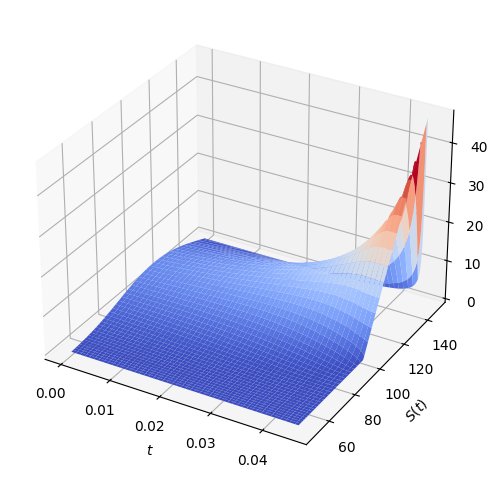

In [72]:
### Uncomment and execute the following two lines if you want to use interactive 3D plots
#plt.close('all')
#%matplotlib widget

### Uncomment and execute the following two lines if you want to use static 3D plots
plt.close('all')
%matplotlib inline

S = K * np.exp(x[1:-1])
t_ori = T - (2 / (sigma ** 2) * t)

### Uncomment and execute the following line only if you obtained no result:
# S, t = np.loadtxt('../shared_materials/objects/6_3_6a.txt'), np.loadtxt('../shared_materials/objects/6_3_6b.txt')

v_S = K * w[::-1, 1:-1] * np.exp(-x[1:-1] / 2 * (q - 1) - (sigma ** 2 / 2) * T * ((q - 1) ** 2 / 4 + q))
S_grid, t_grid = np.meshgrid(S, t)
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(6, 8))
ax.plot_surface(t_grid, S_grid, v_S, cmap=plt.cm.coolwarm)
ax.set_xlabel('$t$')
ax.set_ylabel('$S(t)$')
plt.show()

The "call option price surface" depicted above displays some rather strange stylized facts: In particular, it seems that the computed option prices $V(t)$ are not even monotonically increasing in $S(t)$, which is clearly wrong. The reason for this is that we (wrongly) assumed zero boundary conditions for $S(t) \to \infty$, which we want to change now.

**Task 3.7**: Fill the blank spaces in the function below to incorporate the necessary boundary condition $v(t, S(t)) \approx S(t) - K e^{-r(T - t)}$ for $S(t) \gg K$ for the explicit finite differences scheme.

*Useful Python commands*: `np.linspace`, `np.exp`, `np.zeros`, `np.maximum`, `np.matmul`, `np.dot`, `@`

In [47]:
def call_BS_FiDi_explicit(r, sigma, a, b, m, nu_max, T, K):
    q = 2 * r / (sigma ** 2)
    delta_x = (b - a) / m
    delta_t = (sigma ** 2) * T / (2 * nu_max)
    fidi_lambda = delta_t / (delta_x ** 2)
    
    x = np.linspace(a, b, m + 1)
    t = np.linspace(0, nu_max * delta_t, nu_max + 1)
    r2 = lambda t_val, x_val: np.exp(x_val / 2 * (q + 1) + t_val / 4 * ((q + 1) ** 2)) - np.exp(x_val / 2 * (q - 1) + t_val / 4 * ((q - 1) ** 2)) 
    
    w = np.zeros((nu_max + 1, m + 1))
    w[0] = np.maximum((np.exp(x / 2 * (q + 1)) - np.exp(x / 2 * (q - 1))), 0)
    d = np.zeros(m - 1)

    A = np.diag(np.repeat(fidi_lambda, m - 2), -1) + np.diag(np.repeat(1 - 2 * fidi_lambda, m - 1)) + np.diag(np.repeat(fidi_lambda, m - 2), 1)
    
    for nu in range(nu_max):
        d[-1] = (fidi_lambda / 2) * (r2(t[nu + 1], x[-1]) +r2(t[nu], x[-1]))
        w[nu + 1, 1:-1] = A @ w[nu, 1:-1] + d

    S = K * np.exp(x[1:-1])
    t_original = T - (2 / (sigma ** 2)) * t
    V = K * w[::-1, 1:-1] * np.exp(-x[1:-1] / 2 * (q - 1) - sigma ** 2 / 2 * (T - t_original[..., np.newaxis]) * ((q - 1) ** 2 / 4 + q))
    return t_original, S, V

call_try1 = call_BS_FiDi_explicit(r, sigma, a, b, m, nu_max, T, K)
print(call_try1)

### Uncomment and execute the following line only if you obtained no result:
call_BS_FiDi_explicit1 = types.FunctionType(marshal.load(open('../shared_materials/objects/6_3_7.mar', 'rb')), globals())
call_try2 = call_BS_FiDi_explicit1(r, sigma, a, b, m, nu_max, T, K)
print(call_try2)

(array([1.00000000e+00, 9.99500000e-01, 9.99000000e-01, ...,
       1.00000000e-03, 5.00000000e-04, 1.11022302e-16], shape=(2001,)), array([ 49.99478261,  50.33331171,  50.67413308,  51.01726225,
        51.36271485,  51.71050661,  52.06065337,  52.41317107,
        52.76807577,  53.12538363,  53.48511093,  53.84727405,
        54.21188947,  54.57897381,  54.94854379,  55.32061623,
        55.69520808,  56.0723364 ,  56.45201837,  56.83427127,
        57.21911251,  57.60655963,  57.99663026,  58.38934217,
        58.78471325,  59.1827615 ,  59.58350506,  59.98696216,
        60.39315118,  60.80209063,  61.21379912,  61.62829542,
        62.04559838,  62.46572703,  62.88870048,  63.31453802,
        63.74325902,  64.17488301,  64.60942966,  65.04691874,
        65.48737019,  65.93080407,  66.37724056,  66.8267    ,
        67.27920287,  67.73476976,  68.19342142,  68.65517875,
        69.12006277,  69.58809465,  70.05929572,  70.53368742,
        71.01129136,  71.4921293 ,  71.97622313,

**Task 3.8**: Use the above function `call_BS_FiDi_explicit` with the same input arguments as used before to compute the correct option pricing surface and plot it as in Task 3.6. Interpret your result using a comment. Afterwards, try out some different values of $m$ that are larger than the one that we derived in Task 3.1. What can you observe in the picture?

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/6_3_8.png" width="1050"><details>
  <summary>Interpretation:</summary> Using $m = 163$ and the correct boundary conditions, the left side of the figure shows the correct European call option price surface across the $(t, S)$ grid. If one uses a larger value of $m$ like $m = 170$, the explicit finite difference scheme becomes unstable and gives wrong results (see right side of the figure).

 </details>
</details>

False
[1.00000000e+00 9.99500000e-01 9.99000000e-01 ... 1.00000000e-03
 5.00000000e-04 1.11022302e-16]
[0.000e+00 5.000e-04 1.000e-03 ... 9.990e-01 9.995e-01 1.000e+00]
True
False


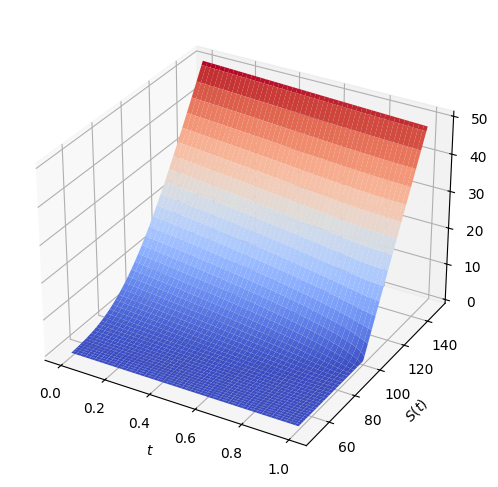

In [48]:
### Uncomment and execute the following two lines if you want to use interactive 3D plots
#plt.close('all')
#%matplotlib widget

### Uncomment and execute the following two lines if you want to use static 3D plots
plt.close('all')
%matplotlib inline

t1, S1, v_S1 = call_BS_FiDi_explicit(r, sigma, a, b, m, nu_max, T, K)

### Uncomment and execute the following line only if you obtained no result:
t2, S2, v_S2 = np.loadtxt('../shared_materials/objects/6_3_8a.txt'), np.loadtxt('../shared_materials/objects/6_3_8b.txt'), np.loadtxt('../shared_materials/objects/6_3_8c.txt')

print(np.array_equal(t1, t2))
print(t1)
print(t2)
print(np.array_equal(S1, S2))
print(np.array_equal(v_S1, v_S2))

S_grid2, t_grid2 = np.meshgrid(S2, t2)
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(6, 8))
ax.plot_surface(t_grid2, S_grid2, v_S2, cmap=plt.cm.coolwarm)
ax.set_xlabel('$t$')
ax.set_ylabel('$S(t)$')

plt.show()

# Interpretation: ...

<br>

## Step 4: Computation of European call option price surfaces using the Crank&ndash;Nicolson method

The instability that arises in the explicit finite difference scheme for values of $m$ that are too large can be avoided by using a more sophisticated finite differences scheme like the Crank&ndash;Nicolson method. To implement the Crank&ndash;Nicolson method, we need some fast method to solve linear systems of equations with tridiagonal coefficient matrices.

**Task 4.1**: Write a function `triagmatrix_inversion(alpha, beta, gamma, b)` that solves the linear system $Ax = b$, where the coefficient matrix $A$ is tridiagonal. The function should receive numpy arrays `alpha`, `beta`, `gamma` and `b` as input arguments containing the constants $\alpha_1, \dots, \alpha_n$, $\beta_1, \dots, \beta_{n-1}$, $\gamma_2, \dots, \gamma_n$ and $b_1, \dots, b_n$, respectively. The function should then perform the tridiagonal matrix inversion algorithm from page 79 of the lecture notes.

In [49]:
def triagmatrix_inversion(alpha, beta, gamma, b): # Back Substitution
    n = len(alpha)
    alpha_hat = np.zeros(n)
    b_hat = np.zeros(n)
    x_hat = np.zeros(n)

    alpha_hat[0] = alpha[0]
    b_hat[0] = b[0]

    for i in range(1, n):
        factor = gamma[i] / alpha_hat[i - 1]
        alpha_hat[i] = alpha[i] - (factor * beta[i - 1])
        b_hat[i] = b[i] - factor * b_hat[i - 1]

    x_hat[-1] = b_hat[-1] / alpha_hat[-1]

    for i in range(n - 2, -1, -1):
        x_hat[i] = (b_hat[i] - beta[i] * x_hat[i + 1]) / alpha_hat[i]
    
    return x_hat

# coba1 = triagmatrix_inversion(alpha, beta, gamma, b)
# print(coba1)
    
### Uncomment and execute the following line only if you obtained no result:
# triagmatrix_inversion1 = types.FunctionType(marshal.load(open('../shared_materials/objects/6_4_1.mar', 'rb')), globals())

**Task 4.2**: Fill the blank spaces in the code below to implement a function `call_BS_FiDi_CN(r, sigma, a, b, m, nu_max, T, K)` that computes the 2-dimensional option price surface $V(t)$ across the $(t, S(t))$ grid in the same way as the function `call_BS_FiDi_explicit` in Task 3.7, but this time using the Crank&ndash;Nicolson scheme instead of the explicit scheme. The function should incorporate appropriate boundary conditions for $S(t) \gg K$ to the algorithm.

*Useful Python commands*: `np.linspace`, `np.exp`, `np.zeros`, `np.maximum`

In [50]:
def call_BS_FiDi_CN(r, sigma, a, b, m, nu_max, T, K):
    q = 2 * r / (sigma ** 2)
    delta_x = (b - a) / m
    delta_t = (sigma ** 2) * T / (2 * nu_max)
    fidi_lambda = delta_t / (delta_x ** 2)
    
    x = np.linspace(a, b, m + 1)
    t = np.linspace(0, nu_max * delta_t, nu_max + 1)
    r2 = lambda t_val, x_val: np.exp(x_val / 2 * (q + 1) + t_val / 4 * ((q + 1) ** 2)) - np.exp(x_val / 2 * (q - 1) + t_val / 4 * ((q - 1) ** 2))
    
    w = np.zeros((nu_max + 1, m + 1))
    w[0] = np.maximum((np.exp(x / 2 * (q + 1)) - np.exp(x / 2 * (q - 1))), 0)
    
    alpha = np.repeat(1 + fidi_lambda, m - 1)
    beta = np.repeat(-fidi_lambda / 2, m - 2)
    gamma = np.repeat(-fidi_lambda / 2, m - 2)

    B_mat = np.diag(np.repeat(fidi_lambda / 2, m - 2), -1) + np.diag(np.repeat(1 - fidi_lambda, m - 1)) + np.diag(np.repeat(fidi_lambda / 2, m - 2), 1)

    gamma_full = np.zeros(m - 1)
    gamma_full[1:] = gamma
    
    for nu in range(nu_max): 
        d = np.zeros(m - 1)
        d[-1] = (fidi_lambda / 2) * (r2(t[nu + 1], x[-1]) +r2(t[nu], x[-1]))

        b_vec = B_mat @ w[nu, 1:-1] + d
        w[nu + 1, 1:-1] = triagmatrix_inversion(alpha, beta, gamma_full, b_vec)

    S = K * np.exp(x[1:-1])
    t_ori = T - (2 / (sigma ** 2)) * t
    V = K * w[::-1, 1:-1] * np.exp(-x[1:-1] / 2 * (q - 1) - sigma ** 2 / 2 * (T - t[:, np.newaxis]) * ((q - 1) ** 2 / 4 + q))
    return t_ori, S, V

### Uncomment and execute the following line only if you obtained no result:
# call_BS_FiDi_CN = types.FunctionType(marshal.load(open('../shared_materials/objects/6_4_2.mar', 'rb')), globals())

**Task 4.3**: Evaluate your function `call_BS_FiDi_CN` on the same input arguments as before but this time with $m = 1000$ to compute the option pricing surface and plot it as in Task 3.6. Interpret your result using a comment and compare it to the result of Task 3.8.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/6_4_3.png" width="550"><details>
  <summary>Interpretation:</summary> There is no visual difference in the option price surfaces returned by the explicit and the Crank&ndash;Nicolson finite difference scheme. The advantage of the Crank&ndash;Nicolson over the explicit scheme lies in the fact that larger values of $m$ can be chosen without losing stability.

 </details>
</details>

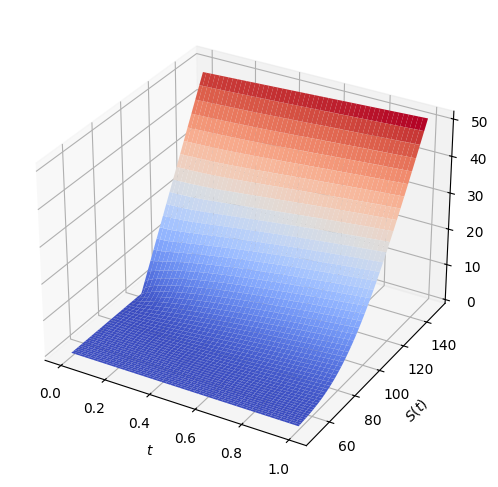

In [73]:
### Uncomment and execute the following two lines if you want to use interactive 3D plots
#plt.close('all')
#%matplotlib widget

### Uncomment and execute the following two lines if you want to use static 3D plots
plt.close('all')
%matplotlib inline

m = 1000
t3, S3, v_S3 = call_BS_FiDi_CN(r, sigma, a, b, m, nu_max, T, K)

### Uncomment and execute the following line only if you obtained no result:
# v_S = np.loadtxt('../shared_materials/objects/6_4_3.txt')

S_grid3, t_grid3 = np.meshgrid(S3, t3)
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(6, 8))
ax.plot_surface(t_grid3, S_grid3, v_S3, cmap=plt.cm.coolwarm)
ax.set_xlabel('$t$')
ax.set_ylabel('$S(t)$')

plt.show()

# Interpretation: ...

<br>

## Step 5: Richardson extrapolation for American options in the binomial model

Richardson extrapolation is a widely used tool to reduce the bias of option pricing computations. It can be used in Monte Carlo simulations where the simulation scheme for the underlying model (like the Euler scheme or the Milshtein scheme) introduces a bias but it is also often used in conjunction with finite difference methods or binomial trees where the discretization of the employed grid or tree introduces a pricing error. In the following, we want to use Richardson extrapolation for the computation of American options in the binomial model.

The code snippet below contains a function `american_put_CRR_anchored` that computes the price of an American put option in the binomial model. It uses the strike-anchored parameterization of the binomial tree from Step 1 of Notebook 02.

In [77]:
def american_put_CRR_anchored(S0, K, T, r, sigma, M):
    delta_t = T / M
    c = (K / S0) ** (2 / M)
    alpha = np.exp(r * delta_t)
    beta = 1 / 2 * (c / alpha + alpha * np.exp(sigma**2 * delta_t))
    u = beta + np.sqrt(beta**2 - c)
    d = c / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    value = np.maximum(K - S0 * u ** (2 * np.arange(M + 1) - M) * c ** np.arange(M, -1, -1), 0)
    for i in range(M - 1, -1, -1):
        upsteps, downsteps = value[1:], value[:-1]
        value = alpha ** (-1) * (q * upsteps + (1 - q) * downsteps)
        payoffs = np.maximum(K - S0 * u ** (2 * np.arange(i + 1) - i) * c ** np.arange(i, -1, -1), 0)
        value = np.maximum(value, payoffs)
    return value[0]

price1 = american_put_CRR_anchored(S0, K, T, r, sigma, M=10000)
print(price1)


11.013087054306494


In [78]:
def american_put_CRR_anchored1(g2, S0, T, r, sigma, M):
    delta_t = T / M
    c = (K / S0) ** (2 / M)
    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - c)
    d = c / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    V[:, M] = g2(S[:, M])

    # Backward induction
    for i in range(M, 0, -1):
        V[:i, i-1] = np.maximum(g2(S[:i, i - 1]), np.exp(-r * delta_t) * (
            q * V[1:i+1, i] + (1 - q) * V[:i, i]
        ))

    return V[0, 0]

K = 100
g2 = lambda S: np.maximum(K - S, 0)  # European Put

price = american_put_CRR_anchored1(g2, S0, T, r, sigma, M=10000)
print(price)

11.013087054300414


First we want to calculate a reference value for the "true" American put price in the Black&ndash;Scholes model. 

**Task 5.1**: Define $S(0) = 80$. Use the function `american_put_CRR_anchored` with $M = 50\,000$ and all other input variables as before to calculate the reference value $V_{\mathrm{ref}}(0)$ and store it in a variable `V0_ref`.

In [79]:
S0 = 80
V0_ref = american_put_CRR_anchored(S0, K, T, r, sigma, 50000)

print(V0_ref)

### Uncomment and execute the following line only if you obtained no result:
# V0_ref = 22.451087678006232

22.451087678006232


Before we use Richardson extrapolation, we have to examine the behaviour of the pricing error of the scheme.

**Task 5.2**: Use the function `american_put_CRR_anchored` in a for-loop to calculate the American put prices $V_{M}(0)$ in the binomial model with the number $M$ of time steps taking the values $M = 50, 55, 60, \dots, 495, 500$. Store these prices in an array `prices_test`. Afterwards, plot the difference between the prices $V_M(0)$ stored in the array `prices_test` and the reference price $V_{\mathrm{ref}}(0)$ stored in the variable `V0_ref` against $M$.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/6_5_2.png" width="550">
</details>

[22.42418448 22.48400567 22.43097716 22.4768266  22.43318719 22.47524699
 22.43559472 22.47121207 22.43746453 22.4701539  22.43881425 22.46720416
 22.43977291 22.46684975 22.44114137 22.46450538 22.44110753 22.46432011
 22.44264373 22.46332649 22.44258665 22.46210036 22.44335631 22.46203274
 22.44410373 22.46099884 22.44378763 22.46047985 22.44469848 22.46037922
 22.44515961 22.45952911 22.44486413 22.45914749 22.44555076 22.45913436
 22.44595997 22.4585805  22.44575573 22.45807238 22.44612581 22.45814711
 22.44656921 22.45787752 22.44658468 22.4572355  22.44650521 22.45727127
 22.4469634  22.45723534 22.44717252 22.45687981 22.44702346 22.4564893
 22.44715713 22.45656823 22.44750009 22.45649968 22.4476169  22.45617467
 22.44745247 22.45590099 22.44761475 22.45597018 22.44789085 22.45592165
 22.44799004 22.45567069 22.4478685  22.45539739 22.44793352 22.45545251
 22.4481769  22.4554487  22.44829758 22.4552932  22.4482502  22.45499334
 22.44817579 22.45499127 22.44837181 22.45503497 22.

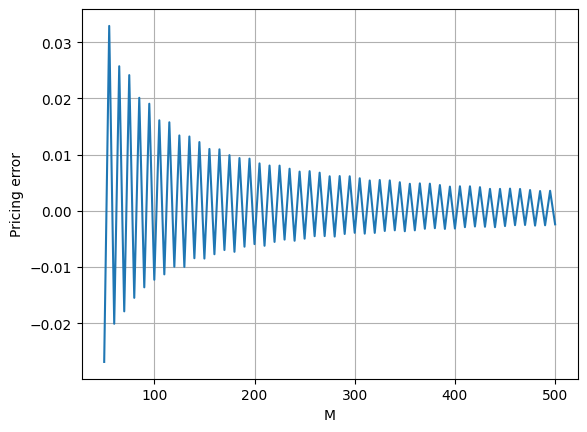

In [80]:
M = np.arange(50, 505, 5)
prices_test = np.zeros(len(M))

for i in range(len(M)):
    prices_test[i] = american_put_CRR_anchored(S0, K, T, r, sigma, M[i])

print(prices_test)

### Uncomment and execute the following line only if you obtained no result:
prices_test1 = np.loadtxt('../shared_materials/objects/6_5_2.txt')
print(np.array_equal(prices_test1, prices_test))

plt.close('all')

plt.plot(M, prices_test - V0_ref)
plt.grid()
plt.ylabel('Pricing error')
plt.xlabel('M')
plt.show()

The above figure shows that for even $M$, the binomial model price $V_M(0)$ overshoots the "true" reference price $V_{\mathrm{ref}}(0)$ of the American option, while for odd $M$ the price $V_M(0)$ undershoots the reference price. This suggests that it makes sense to use Richardson extrapolation in the sense that one considers the linear combination $2V_{4M}(0) - V_{2M}(0)$ (or, alternatively, the linear combination $2V_{4M + 1}(0) - V_{2M + 1}(0)$). We now want to examine how much faster this extrapolated value converges to the "true" price as $M \to \infty$ compared to the crude estimates.

**Task 5.3**: Use the function `american_put_CRR_anchored` in a for-loop to calculate the American put prices $V_{2M}(0)$ in the binomial model with the number $M$ of time steps taking the values $M = 20, 40, 60, \dots, 2480, 2500$. Store these prices in an array `prices`. Afterwards, use the function `american_put_CRR_anchored` in a for-loop to calculate the linear combinations $2V_{4M}(0) - V_{2M}(0)$ and store them in an array `prices_richardson`.

In [81]:
M1 = np.arange(20, 2520, 20)
prices_crude = np.zeros(len(M1))
prices_richardson = np.zeros(len(M1))

for i in range(len(M1)):
    v_2m = american_put_CRR_anchored(S0, K, T, r, sigma, 2 * M1[i])
    v_4m = american_put_CRR_anchored(S0, K, T, r, sigma, 4 * M1[i])

    prices_crude[i] = v_2m
    prices_richardson[i] = 2 * v_4m - v_2m

print(prices_crude)
print(prices_richardson)

### Uncomment and execute the following line only if you obtained no result:
prices_crude1, prices_richardson1 = np.loadtxt('../shared_materials/objects/6_5_3.txt')
#print(prices_crude1)
#print(prices_richardson1)

print(np.array_equal(prices_crude, prices_crude1)) # True
print(np.array_equal(prices_richardson1, prices_richardson)) # True

[22.42037106 22.43559472 22.44114137 22.44335631 22.44515961 22.44575573
 22.44650521 22.44715713 22.44761475 22.44793352 22.44817579 22.44845632
 22.44879144 22.44900243 22.44909199 22.44911967 22.44931532 22.44947106
 22.44947651 22.44955956 22.44970526 22.44969003 22.44979531 22.44986235
 22.44983912 22.44997506 22.44995325 22.45004463 22.45005503 22.45009583
 22.45013599 22.4501421  22.4502003  22.45019127 22.45025427 22.45024326
 22.45029918 22.4502968  22.45033637 22.45034848 22.45036721 22.45039636
 22.45039269 22.4504358  22.45041491 22.45046541 22.45044135 22.45048541
 22.45049047 22.45049768 22.4505282  22.4505089  22.4505491  22.45054005
 22.45055739 22.45057946 22.45056254 22.45059696 22.45059311 22.45060044
 22.45062442 22.45060529 22.45063304 22.45064309 22.45063211 22.45065916
 22.45065666 22.45065817 22.45068043 22.45066861 22.45068117 22.45069847
 22.45068287 22.450701   22.4507145  22.45069932 22.45071799 22.45072944
 22.45071503 22.45073277 22.45074351 22.45072961 22

**Task 5.4**: Plot the crude price estimates stored in the array `prices_crude` against $M = 40, 80, 120, \dots, 4960, 5000$. Afterwards, plot the Richardson extrapolations stored in the array `prices_richardson` against $M = 40, 80, 120, \dots, 4960, 5000$. Use the function `plt.semilogx` instead of `plt.plot` to obtain a logarithmic spacing of the $x$ axis. Draw a horizontal line at the height of the reference price $V_{\mathrm{ref}}(0)$ stored in the variable `V0_ref` and interpret your result using a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/6_5_4.png" width="550"><details>
  <summary>Interpretation:</summary> While the convergence order of the crude binomial approximation to the American option price is 1 (i.e. the absolute approximation error behaves roughly like $M^{-1}$), the Richardson extrapolation shows a much faster convergence to the reference American option price. Hence, a much smaller number $M$ and therefore also a much smaller computation time is needed when using Richardson extrapolation to achieve the same accuracy of the price approximation.

 </details>
</details>

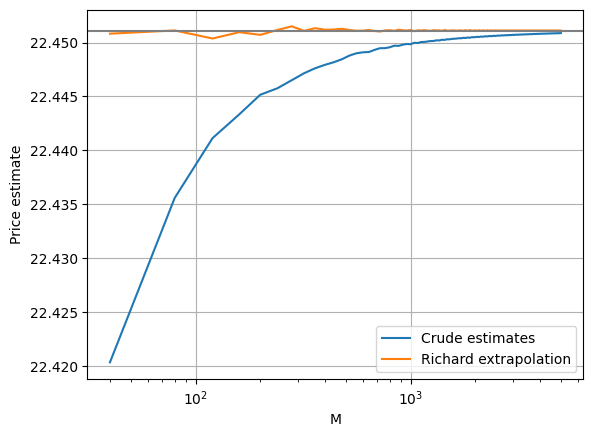

In [83]:
M_plot = np.arange(40, 5040, 40)

plt.close('all')

plt.semilogx(M_plot, prices_crude, label = 'Crude estimates')
plt.semilogx(M_plot, prices_richardson, label = 'Richard extrapolation')
plt.axhline(V0_ref, color = 'grey')
plt.grid()
plt.xlabel('M')
plt.ylabel('Price estimate')
plt.legend()

plt.show()

# Interpretation: ...